# Buy Fee Response Model v4 — Volume Attrition, Conversion, RPU & Revenue

## Problem statement
Pricing needs a defensible way to answer:

> If Buy Fee is increased by **$10, $15, $20, $25, or $30**, what is the expected impact on **sold volume, conversion, Revenue per Unit (RPU), and total Buy Fee revenue**?

The existing *Buy Fee Increase Recommendations - In-Lane TTM Aug26_v1* report uses an approximate benchmark of **-0.50 volume elasticity**: a 1% Buy Fee increase is assumed to produce about a 0.5% volume decline. This notebook treats that as a **benchmark to validate**, not as ground truth.

## Key design decisions agreed in the project
1. A historical fee-change event exists **only when `BUYFEE_CHANGE_STATUS == "Change"`**.
2. Repeated VIN rows carrying the same fee-change information do **not** create repeated treatment events.
3. Events are deduplicated at **Location × Lane × Price Tier × Change Date**.
4. The schedule treatment is derived from **`PREVIOUS_BUYFEE + BUYFEE_CHANGE_AMOUNT`**. `BUYFEE-FINAL`/realized fee is used for realized RPU/pass-through analysis, not to invent change events.
5. Primary volume outcome is **sold units**. Registered/offered units are retained as a supply/context measure.
6. Effects are evaluated at **4-, 8-, and 12-week** windows with the event week excluded.
7. The model uses a **chronological holdout**, not a random train/test split.
8. Final scenarios compare the historical-report benchmark with an empirical model and include reliability flags.

## Outputs
The notebook produces:
- Data and event-definition audits
- Unique fee-change event table
- 4/8/12-week event study
- Control-adjusted Volume, Conversion, and RPU effects
- Test of the report's -0.50 elasticity assumption
- Chronologically validated Ridge + Random Forest models
- +$10 / +$15 / +$20 / +$25 / +$30 scenario results
- Revenue impact estimates
- Model-readiness / corporate-use diagnostics
- CSV exports for Excel/Tableau review

**v4 fix:** the first executable cell now validates paths and loads both CSVs, so `vin_raw` and `weekly_raw` are defined before schema validation.

## 0. Run this cell first — configuration + file validation + CSV loading
This cell is intentionally self-contained. It validates the exact Windows paths, creates the output folder, imports pandas/numpy, defines the robust CSV reader, and loads `vin_raw` and `weekly_raw`. After it finishes, continue with **Run All Below**.

In [1]:
from pathlib import Path
import math, json, warnings, re
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)

# ============================================================
# CONFIRMED INPUT FOLDER / FILES
# ============================================================
DATA_FOLDER = Path(
    r"C:\Users\ViditSheth\OneDrive - America's Auto Auction\Finance - Documents\FP&A\Data Analytics\Development\Vidit_Sanbox\Buy Fee Model Phase 2\Rough Area\Volume Attirtion"
)

VIN_FILE = DATA_FOLDER / "VIN_LEVEL_DATA_WITH_DATES_AND_SALE_PRICE.csv"
WEEKLY_FILE = DATA_FOLDER / "WEEKLY_VOLUME_ATTRITION.csv"
REPORT_FILE = DATA_FOLDER / "Buy Fee Increase Recommendations - In-Lane TTM Aug26_v1.xlsx"

OUTPUT_DIR = DATA_FOLDER / "buy_fee_model_outputs_v4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Backward-compatible names used later in the notebook
VIN_CSV = VIN_FILE
WEEKLY_CSV = WEEKLY_FILE
REPORT_XLSX = REPORT_FILE

# ============================================================
# ANALYSIS SETTINGS
# ============================================================
EVENT_WINDOWS = (4, 8, 12)
PRIMARY_WINDOW = 8
PRICE_TIER_SIZE = 1000
SCENARIO_INCREASES = [10, 15, 20, 25, 30]
REPORT_ELASTICITY = -0.50
RANDOM_STATE = 42
MIN_EVENTS_TO_TRAIN = 300
MIN_TEST_EVENTS = 50
MIN_WEEKS_EACH_SIDE = 0.75
CONTROL_MIN_SEGMENTS = 10
EXPLICIT_PRICE_TIER_COL = None

# ============================================================
# FILE VALIDATION
# ============================================================
print("=" * 80)
print("BUY FEE MODEL V4 — CONFIGURATION + DATA LOAD")
print("=" * 80)
print("Data folder exists:", DATA_FOLDER.exists())
print("VIN exists:", VIN_FILE.exists(), "->", VIN_FILE)
print("Weekly exists:", WEEKLY_FILE.exists(), "->", WEEKLY_FILE)
print("Report exists:", REPORT_FILE.exists(), "->", REPORT_FILE)
print("Output folder:", OUTPUT_DIR)

required_paths = {"VIN CSV": VIN_FILE, "Weekly CSV": WEEKLY_FILE}
missing_paths = [f"{name}: {path}" for name, path in required_paths.items() if not path.exists()]
if missing_paths:
    print("\nCSV files visible in DATA_FOLDER:")
    if DATA_FOLDER.exists():
        for i, f in enumerate(DATA_FOLDER.glob("*.csv")):
            print(f"  {i}: {f.name}")
    raise FileNotFoundError("Required input file(s) missing:\n" + "\n".join(missing_paths))

# ============================================================
# ROBUST CSV LOADER
# ============================================================
def read_csv_robust(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Input file not found: {path}")
    last_error = None
    for enc in ["utf-8", "utf-8-sig", "cp1252", "latin1"]:
        try:
            df = pd.read_csv(path, encoding=enc, low_memory=False)
            print(f"Loaded {path.name}: {len(df):,} rows x {df.shape[1]:,} columns using {enc}")
            return df
        except UnicodeDecodeError as exc:
            last_error = exc
    raise last_error

# ============================================================
# LOAD BOTH MODEL INPUTS HERE — vin_raw is defined in this cell
# ============================================================
print("\nLoading VIN-level file...")
vin_raw = read_csv_robust(VIN_FILE)

print("\nLoading weekly file...")
weekly_raw = read_csv_robust(WEEKLY_FILE)

print("\n" + "=" * 80)
print("DATA LOAD COMPLETE")
print("=" * 80)
print(f"VIN rows:    {len(vin_raw):,}")
print(f"Weekly rows: {len(weekly_raw):,}")
print("vin_raw defined:", "vin_raw" in globals())
print("weekly_raw defined:", "weekly_raw" in globals())
print("\nContinue to the next cell.")

BUY FEE MODEL V4 — CONFIGURATION + DATA LOAD
Data folder exists: True
VIN exists: True -> C:\Users\ViditSheth\OneDrive - America's Auto Auction\Finance - Documents\FP&A\Data Analytics\Development\Vidit_Sanbox\Buy Fee Model Phase 2\Rough Area\Volume Attirtion\VIN_LEVEL_DATA_WITH_DATES_AND_SALE_PRICE.csv
Weekly exists: True -> C:\Users\ViditSheth\OneDrive - America's Auto Auction\Finance - Documents\FP&A\Data Analytics\Development\Vidit_Sanbox\Buy Fee Model Phase 2\Rough Area\Volume Attirtion\WEEKLY_VOLUME_ATTRITION.csv
Report exists: True -> C:\Users\ViditSheth\OneDrive - America's Auto Auction\Finance - Documents\FP&A\Data Analytics\Development\Vidit_Sanbox\Buy Fee Model Phase 2\Rough Area\Volume Attirtion\Buy Fee Increase Recommendations - In-Lane TTM Aug26_v1.xlsx
Output folder: C:\Users\ViditSheth\OneDrive - America's Auto Auction\Finance - Documents\FP&A\Data Analytics\Development\Vidit_Sanbox\Buy Fee Model Phase 2\Rough Area\Volume Attirtion\buy_fee_model_outputs_v4

Loading VIN-l

## 1. Modeling imports
The CSVs were already loaded in Section 0. This cell imports plotting and scikit-learn components only.

In [2]:
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Defensive check so an out-of-order run gives a clear instruction.
if "vin_raw" not in globals() or "weekly_raw" not in globals():
    raise RuntimeError("Run Section 0 first. It validates the paths and loads vin_raw + weekly_raw.")

print("Modeling libraries loaded; input data is available.")

Modeling libraries loaded; input data is available.


## 2. Schema audit and standardized fields
This section validates the required columns before any model is built.

In [3]:
if "vin_raw" not in globals():
    raise RuntimeError("vin_raw is not loaded. Run Section 0 first, then run cells in order.")

REQUIRED_VIN = [
    "VRVIN", "VRLOCATION", "LANE", "VRSALEDATE",
    "REGISTERED_UNITS", "SOLD_UNITS", "SOLD_FLAG",
    "SALEAMT_FINAL", "BUYFEE-FINAL",
    "BUYFEE_CHANGE_STATUS", "BUYFEE_CHANGE_DATE",
    "PREVIOUS_BUYFEE", "BUYFEE_CHANGE_AMOUNT"
]

missing = [c for c in REQUIRED_VIN if c not in vin_raw.columns]
if missing:
    raise ValueError(f"VIN CSV is missing required columns: {missing}")

print("Required VIN columns found.")
print("VIN rows:", f"{len(vin_raw):,}")
print("Weekly rows:", f"{len(weekly_raw):,}")
print("Date range raw:", vin_raw["VRSALEDATE"].head(3).tolist(), "...")

Required VIN columns found.
VIN rows: 5,504,525
Weekly rows: 1,988,715
Date range raw: ['2024-03-21', '2025-09-23', '2023-06-29'] ...


In [4]:
def parse_mixed_date(s):
    # Supports YYYYMMDD, Excel-like strings, and normal date text.
    x = s.astype("string").str.strip()
    out = pd.to_datetime(x, errors="coerce")
    mask = out.isna() & x.str.fullmatch(r"\d{8}", na=False)
    if mask.any():
        out.loc[mask] = pd.to_datetime(x.loc[mask], format="%Y%m%d", errors="coerce")
    return out

vin = vin_raw.copy()
vin["sale_date"] = parse_mixed_date(vin["VRSALEDATE"])
vin["change_date"] = parse_mixed_date(vin["BUYFEE_CHANGE_DATE"])
vin["week_start"] = vin["sale_date"] - pd.to_timedelta(vin["sale_date"].dt.weekday, unit="D")
vin["change_week"] = vin["change_date"] - pd.to_timedelta(vin["change_date"].dt.weekday, unit="D")

for c in ["REGISTERED_UNITS", "SOLD_UNITS", "SALEAMT_FINAL", "BUYFEE-FINAL", "PREVIOUS_BUYFEE", "BUYFEE_CHANGE_AMOUNT"]:
    vin[c] = pd.to_numeric(vin[c], errors="coerce")

# Normalize categorical identifiers
for c in ["VRLOCATION", "LANE", "BUYFEE_CHANGE_STATUS"]:
    vin[c] = vin[c].astype("string").str.strip()
vin["VRLOCATION"] = vin["VRLOCATION"].str.upper()
vin["LANE"] = vin["LANE"].fillna("UNKNOWN").str.upper()
vin["change_status_norm"] = vin["BUYFEE_CHANGE_STATUS"].str.upper()

# Sold flag: use provided SOLD_FLAG when available; fall back to business rule if needed.
def normalize_bool(s):
    txt = s.astype("string").str.strip().str.upper()
    return txt.isin(["TRUE", "1", "Y", "YES", "SOLD"])

vin["sold_flag_model"] = normalize_bool(vin["SOLD_FLAG"])
if vin["sold_flag_model"].sum() == 0 and {"VRSTATUS","VRINVOICE","VRIFORTRY"}.issubset(vin.columns):
    st = vin["VRSTATUS"].astype("string").str.upper().str.strip()
    inv = vin["VRINVOICE"].astype("string").str.upper().str.strip()
    ift = vin["VRIFORTRY"].astype("string").str.upper().str.strip()
    vin["sold_flag_model"] = ((st.eq("HST") & ~inv.eq("RETURN")) | (st.eq("SLD") & ~ift.eq("Y")))

# Price tier
if EXPLICIT_PRICE_TIER_COL and EXPLICIT_PRICE_TIER_COL in vin.columns:
    vin["price_tier"] = vin[EXPLICIT_PRICE_TIER_COL].astype("string").str.strip()
    vin["price_tier_low"] = pd.to_numeric(vin[EXPLICIT_PRICE_TIER_COL], errors="coerce")
else:
    amt = vin["SALEAMT_FINAL"]
    low = np.floor(amt / PRICE_TIER_SIZE) * PRICE_TIER_SIZE
    vin["price_tier_low"] = low
    vin["price_tier"] = np.where(
        low.notna(),
        low.astype("Int64").astype("string") + "-" + (low + PRICE_TIER_SIZE).astype("Int64").astype("string"),
        "UNASSIGNED"
    )

print("Standardized date range:", vin["sale_date"].min(), "to", vin["sale_date"].max())
print("Locations:", vin["VRLOCATION"].nunique())
print("Lanes:", vin["LANE"].nunique())
print("Price tiers:", vin.loc[vin["price_tier"].ne("UNASSIGNED"), "price_tier"].nunique())

Standardized date range: 2022-12-26 00:00:00 to 2026-12-25 00:00:00
Locations: 53
Lanes: 361
Price tiers: 371


## 3. Critical event-definition audit
**Only `BUYFEE_CHANGE_STATUS == "Change"` creates a fee-change event.**

This prevents the 6.9M VIN rows from being misinterpreted as millions of independent pricing decisions.

In [5]:
status_counts = vin["change_status_norm"].value_counts(dropna=False).rename_axis("Status").reset_index(name="VIN_Rows")
display(status_counts)

change_rows = vin[vin["change_status_norm"].eq("CHANGE")].copy()
print("VIN rows marked CHANGE:", f"{len(change_rows):,}")
print("Unique change dates:", f"{change_rows['change_date'].nunique():,}")
print("Unique Location × Change Date:", f"{change_rows[['VRLOCATION','change_date']].drop_duplicates().shape[0]:,}")
print("Unique Location × Lane × Change Date:", f"{change_rows[['VRLOCATION','LANE','change_date']].drop_duplicates().shape[0]:,}")

,Status,VIN_Rows
0,NO CHANGE,5265823
1,CHANGE,238702


VIN rows marked CHANGE: 238,702
Unique change dates: 10
Unique Location × Change Date: 164
Unique Location × Lane × Change Date: 2,117


## 4. Build the unique fee-change event table
An event is one unique **Location × Lane × Price Tier × Change Date**.

If repeated VIN rows disagree about `PREVIOUS_BUYFEE` or `BUYFEE_CHANGE_AMOUNT` inside the same event key, the event is flagged as ambiguous and excluded from model training until reviewed.

In [6]:
EVENT_KEY = ["VRLOCATION", "LANE", "price_tier", "change_date"]

# Exclude unusable rows before deduplication
cr = change_rows[
    change_rows["change_date"].notna()
    & change_rows["price_tier"].ne("UNASSIGNED")
    & change_rows["PREVIOUS_BUYFEE"].notna()
    & change_rows["BUYFEE_CHANGE_AMOUNT"].notna()
].copy()

# Audit whether multiple fee definitions exist inside the same logical event.
fee_def_audit = (
    cr.groupby(EVENT_KEY, dropna=False)
      .agg(
          prior_fee_n=("PREVIOUS_BUYFEE", "nunique"),
          change_amt_n=("BUYFEE_CHANGE_AMOUNT", "nunique"),
          source_vin_rows=("VRVIN", "size"),
          source_unique_vins=("VRVIN", "nunique"),
          previous_fee=("PREVIOUS_BUYFEE", "median"),
          fee_change_amount=("BUYFEE_CHANGE_AMOUNT", "median"),
          price_tier_low=("price_tier_low", "median")
      )
      .reset_index()
)

fee_def_audit["event_definition_clean"] = fee_def_audit["prior_fee_n"].eq(1) & fee_def_audit["change_amt_n"].eq(1)
fee_def_audit["new_fee"] = fee_def_audit["previous_fee"] + fee_def_audit["fee_change_amount"]
fee_def_audit["fee_change_pct"] = np.where(
    fee_def_audit["previous_fee"].abs() > 1e-9,
    fee_def_audit["fee_change_amount"] / fee_def_audit["previous_fee"],
    np.nan
)
fee_def_audit["fee_direction"] = np.select(
    [fee_def_audit["fee_change_amount"] > 0, fee_def_audit["fee_change_amount"] < 0],
    ["Increase", "Decrease"],
    default="Zero"
)
fee_def_audit["change_week"] = fee_def_audit["change_date"] - pd.to_timedelta(fee_def_audit["change_date"].dt.weekday, unit="D")
fee_def_audit["event_id"] = np.arange(1, len(fee_def_audit) + 1)

events_all = fee_def_audit.copy()
events = events_all[events_all["event_definition_clean"] & events_all["fee_change_amount"].ne(0)].copy()

print("Raw logical events:", f"{len(events_all):,}")
print("Clean non-zero events:", f"{len(events):,}")
print("Ambiguous fee-definition events excluded:", f"{(~events_all['event_definition_clean']).sum():,}")
print("Duplicate event keys after dedupe:", events.duplicated(EVENT_KEY).sum())
print("Increase events:", f"{events['fee_direction'].eq('Increase').sum():,}")
print("Decrease events:", f"{events['fee_direction'].eq('Decrease').sum():,}")

display(events[["VRLOCATION","LANE","price_tier","change_date","previous_fee","new_fee","fee_change_amount","fee_change_pct","source_vin_rows"]].head(10))

Raw logical events: 36,117
Clean non-zero events: 19,636
Ambiguous fee-definition events excluded: 16,481
Duplicate event keys after dedupe: 0
Increase events: 19,107
Decrease events: 529


,VRLOCATION,LANE,price_tier,change_date,previous_fee,new_fee,fee_change_amount,fee_change_pct,source_vin_rows
0,ATLANTA,.A,9000-10000,2026-09-01,135.0,155.0,20.0,0.148148,1
3,ATLANTA,A,0-1000,2026-09-01,305.0,325.0,20.0,0.065574,1
13,ATLANTA,A,12000-13000,2023-07-01,485.0,495.0,10.0,0.020619,3
21,ATLANTA,A,14000-15000,2023-07-01,495.0,505.0,10.0,0.020202,1
28,ATLANTA,A,16000-17000,2023-12-01,110.0,120.0,10.0,0.090909,7
29,ATLANTA,A,16000-17000,2025-07-01,555.0,635.0,80.0,0.144144,1
31,ATLANTA,A,17000-18000,2023-07-01,510.0,520.0,10.0,0.019608,3
35,ATLANTA,A,18000-19000,2023-07-01,515.0,525.0,10.0,0.019417,2
38,ATLANTA,A,18000-19000,2026-09-01,135.0,155.0,20.0,0.148148,2
39,ATLANTA,A,19000-20000,2023-07-01,515.0,525.0,10.0,0.019417,1


## 5. Build weekly Location × Lane × Price Tier panel from VIN history
This is the behavioral panel used to measure what happened around each fee change.

In [7]:
work = vin[
    vin["week_start"].notna()
    & vin["price_tier"].ne("UNASSIGNED")
].copy()

# One VIN can appear multiple times in operational data. Count unique VINs for offered/sold volume where possible.
work["sold_vin"] = np.where(work["sold_flag_model"], work["VRVIN"], pd.NA)
work["realized_fee_revenue"] = np.where(
    work["sold_flag_model"] & work["BUYFEE-FINAL"].notna(),
    work["BUYFEE-FINAL"],
    0.0
)

panel = (
    work.groupby(["VRLOCATION","LANE","price_tier","price_tier_low","week_start"], dropna=False)
        .agg(
            registered_units=("VRVIN", "nunique"),
            sold_units=("sold_vin", "nunique"),
            buyfee_revenue=("realized_fee_revenue", "sum"),
            avg_sale_price=("SALEAMT_FINAL", "mean"),
            avg_realized_fee=("BUYFEE-FINAL", "mean"),
            avg_mileage=("VRMILEAGE", "mean") if "VRMILEAGE" in work.columns else ("SALEAMT_FINAL", "size")
        )
        .reset_index()
)
panel["conversion"] = np.where(panel["registered_units"] > 0, panel["sold_units"] / panel["registered_units"], np.nan)
panel["rpu"] = np.where(panel["sold_units"] > 0, panel["buyfee_revenue"] / panel["sold_units"], np.nan)

print("Weekly segment rows:", f"{len(panel):,}")
print("Weekly date range:", panel["week_start"].min(), "to", panel["week_start"].max())
print("Unique segments:", f"{panel[['VRLOCATION','LANE','price_tier']].drop_duplicates().shape[0]:,}")

Weekly segment rows: 1,685,430
Weekly date range: 2022-12-26 00:00:00 to 2026-12-21 00:00:00
Unique segments: 55,373


## 6. Fast 4/8/12-week event study
The event week is excluded. A segment must have sufficient weekly coverage on both sides to be considered reliable.

The lookup dictionary prevents repeatedly scanning the full weekly panel for every event, which is important for multi-million-row VIN histories.

In [8]:
panel_lookup = {
    key: grp.sort_values("week_start").copy()
    for key, grp in panel.groupby(["VRLOCATION","LANE","price_tier"], sort=False)
}


def safe_pct_change(post, pre):
    if pd.isna(pre) or pd.isna(post) or abs(pre) < 1e-12:
        return np.nan
    return (post - pre) / pre


def summarize_period(df):
    if df is None or df.empty:
        return {
            "weeks": 0, "registered_pw": np.nan, "sold_pw": np.nan,
            "conversion": np.nan, "rpu": np.nan, "avg_sale_price": np.nan,
            "avg_realized_fee": np.nan
        }
    reg = df["registered_units"].sum()
    sold = df["sold_units"].sum()
    revenue = df["buyfee_revenue"].sum()
    weeks = df["week_start"].nunique()
    return {
        "weeks": weeks,
        "registered_pw": reg / weeks if weeks else np.nan,
        "sold_pw": sold / weeks if weeks else np.nan,
        "conversion": sold / reg if reg > 0 else np.nan,
        "rpu": revenue / sold if sold > 0 else np.nan,
        "avg_sale_price": np.average(df["avg_sale_price"].fillna(0), weights=np.maximum(df["registered_units"],1)) if len(df) else np.nan,
        "avg_realized_fee": np.average(df["avg_realized_fee"].fillna(0), weights=np.maximum(df["sold_units"],1)) if len(df) else np.nan,
    }


def event_study(events, panel_lookup, windows=(4,8,12)):
    rows=[]
    for _, e in events.iterrows():
        key=(e["VRLOCATION"], e["LANE"], e["price_tier"])
        seg=panel_lookup.get(key)
        if seg is None or seg.empty:
            continue

        out={
            "event_id":e["event_id"], "VRLOCATION":e["VRLOCATION"], "LANE":e["LANE"],
            "price_tier":e["price_tier"], "price_tier_low":e["price_tier_low"],
            "event_date":e["change_date"], "event_week":e["change_week"],
            "previous_fee":e["previous_fee"], "new_fee":e["new_fee"],
            "fee_change_amount":e["fee_change_amount"], "fee_change_pct":e["fee_change_pct"],
            "fee_direction":e["fee_direction"],
            "event_year":e["change_date"].year, "event_month":e["change_date"].month,
            "source_vin_rows":e["source_vin_rows"]
        }

        for w in windows:
            pre_start=e["change_week"]-pd.Timedelta(weeks=w)
            pre_end=e["change_week"]-pd.Timedelta(weeks=1)
            post_start=e["change_week"]+pd.Timedelta(weeks=1)
            post_end=e["change_week"]+pd.Timedelta(weeks=w)
            pre=seg[seg["week_start"].between(pre_start,pre_end)]
            post=seg[seg["week_start"].between(post_start,post_end)]
            a=summarize_period(pre); b=summarize_period(post)
            for k,v in a.items(): out[f"pre_{w}w_{k}"]=v
            for k,v in b.items(): out[f"post_{w}w_{k}"]=v
            out[f"volume_change_pct_{w}w"] = safe_pct_change(b["sold_pw"], a["sold_pw"])
            out[f"registered_change_pct_{w}w"] = safe_pct_change(b["registered_pw"], a["registered_pw"])
            out[f"conversion_change_pp_{w}w"] = ((b["conversion"]-a["conversion"])*100 if pd.notna(a["conversion"]) and pd.notna(b["conversion"]) else np.nan)
            out[f"rpu_change_pct_{w}w"] = safe_pct_change(b["rpu"], a["rpu"])
            out[f"rpu_change_dollar_{w}w"] = (b["rpu"]-a["rpu"] if pd.notna(a["rpu"]) and pd.notna(b["rpu"]) else np.nan)
            out[f"coverage_ok_{w}w"] = (a["weeks"] >= math.ceil(w*MIN_WEEKS_EACH_SIDE)) and (b["weeks"] >= math.ceil(w*MIN_WEEKS_EACH_SIDE))
        rows.append(out)
    return pd.DataFrame(rows)

event_df = event_study(events, panel_lookup, EVENT_WINDOWS)
print("Event-study rows:", f"{len(event_df):,}")
for w in EVENT_WINDOWS:
    print(f"{w}W adequate coverage:", f"{event_df[f'coverage_ok_{w}w'].sum():,}")

Event-study rows: 19,636
4W adequate coverage: 2,497
8W adequate coverage: 2,067
12W adequate coverage: 1,993


## 7. Exclude overlapping / contaminated events
If another fee change occurs in the same segment inside the pre/post analysis window, the event can mix multiple treatments. Those events are flagged and excluded from the primary model.

In [9]:
segment_event_weeks = {
    key: sorted(grp["change_week"].dropna().unique())
    for key, grp in events.groupby(["VRLOCATION","LANE","price_tier"], sort=False)
}


def has_overlap(row, weeks=PRIMARY_WINDOW):
    key=(row["VRLOCATION"],row["LANE"],row["price_tier"])
    weeks_arr=segment_event_weeks.get(key, [])
    lo=row["event_week"]-pd.Timedelta(weeks=weeks)
    hi=row["event_week"]+pd.Timedelta(weeks=weeks)
    return sum((pd.Timestamp(x) >= lo) and (pd.Timestamp(x) <= hi) for x in weeks_arr) > 1

event_df["overlap_primary_window"] = event_df.apply(has_overlap, axis=1)
print("Events contaminated by another change within ±", PRIMARY_WINDOW, "weeks:", f"{event_df['overlap_primary_window'].sum():,}")

Events contaminated by another change within ± 8 weeks: 896


## 8. Control-adjusted outcomes
A raw before/after decline is not automatically caused by Buy Fee. This section estimates a contemporaneous counterfactual using **other locations in the same price tier** that did not change fee during the event window.

For each event, the control effect is the median change among eligible segments. The treated minus control difference becomes the primary target.

In [10]:
# Build a set of changed segment-weeks for contamination checks.
changed_weeks_by_segment = {
    key: set(pd.to_datetime(grp["change_week"].dropna()).tolist())
    for key, grp in events.groupby(["VRLOCATION","LANE","price_tier"], sort=False)
}

# Tier lookup reduces control search size.
tier_panel_lookup = {
    tier: grp.copy()
    for tier, grp in panel.groupby("price_tier", sort=False)
}


def control_changes_for_event(row, w=PRIMARY_WINDOW):
    tier=row["price_tier"]
    tp=tier_panel_lookup.get(tier)
    if tp is None or tp.empty:
        return None
    pre_start=row["event_week"]-pd.Timedelta(weeks=w)
    pre_end=row["event_week"]-pd.Timedelta(weeks=1)
    post_start=row["event_week"]+pd.Timedelta(weeks=1)
    post_end=row["event_week"]+pd.Timedelta(weeks=w)
    lo=row["event_week"]-pd.Timedelta(weeks=w)
    hi=row["event_week"]+pd.Timedelta(weeks=w)

    candidates=[]
    for (loc,lane,pt), seg in tp.groupby(["VRLOCATION","LANE","price_tier"], sort=False):
        if loc == row["VRLOCATION"]:
            continue
        change_weeks=changed_weeks_by_segment.get((loc,lane,pt),set())
        if any(lo <= cw <= hi for cw in change_weeks):
            continue
        pre=seg[seg["week_start"].between(pre_start,pre_end)]
        post=seg[seg["week_start"].between(post_start,post_end)]
        a=summarize_period(pre); b=summarize_period(post)
        if a["weeks"] < math.ceil(w*MIN_WEEKS_EACH_SIDE) or b["weeks"] < math.ceil(w*MIN_WEEKS_EACH_SIDE):
            continue
        candidates.append({
            "volume":safe_pct_change(b["sold_pw"],a["sold_pw"]),
            "conversion_pp":((b["conversion"]-a["conversion"])*100 if pd.notna(a["conversion"]) and pd.notna(b["conversion"]) else np.nan),
            "rpu_pct":safe_pct_change(b["rpu"],a["rpu"]),
            "rpu_dollar":((b["rpu"]-a["rpu"]) if pd.notna(a["rpu"]) and pd.notna(b["rpu"]) else np.nan)
        })
    if len(candidates) < CONTROL_MIN_SEGMENTS:
        return {"n":len(candidates),"volume":np.nan,"conversion_pp":np.nan,"rpu_pct":np.nan,"rpu_dollar":np.nan}
    c=pd.DataFrame(candidates)
    return {
        "n":len(c), "volume":c["volume"].median(), "conversion_pp":c["conversion_pp"].median(),
        "rpu_pct":c["rpu_pct"].median(), "rpu_dollar":c["rpu_dollar"].median()
    }

# Control matching can be the slowest section. Restrict to adequately covered, non-overlapping events.
primary_mask = event_df[f"coverage_ok_{PRIMARY_WINDOW}w"] & ~event_df["overlap_primary_window"]
primary_idx = event_df.index[primary_mask]
print("Events entering control matching:", f"{len(primary_idx):,}")

# Initialize columns so tiny samples with zero eligible events still run cleanly.
for col in [
    "control_n","control_volume_change","control_conversion_change_pp",
    "control_rpu_change_pct","control_rpu_change_dollar"
]:
    event_df[col] = np.nan

control_records=[]
for n, idx in enumerate(primary_idx, start=1):
    row=event_df.loc[idx]
    res=control_changes_for_event(row, PRIMARY_WINDOW)
    if res is None:
        continue
    control_records.append((idx,res))
    if n % 500 == 0:
        print(f"Control matched {n:,}/{len(primary_idx):,} events")

for idx,res in control_records:
    event_df.loc[idx,"control_n"] = res["n"]
    event_df.loc[idx,"control_volume_change"] = res["volume"]
    event_df.loc[idx,"control_conversion_change_pp"] = res["conversion_pp"]
    event_df.loc[idx,"control_rpu_change_pct"] = res["rpu_pct"]
    event_df.loc[idx,"control_rpu_change_dollar"] = res["rpu_dollar"]

W=PRIMARY_WINDOW
event_df["adj_volume_change_pct"] = event_df[f"volume_change_pct_{W}w"] - event_df["control_volume_change"]
event_df["adj_conversion_change_pp"] = event_df[f"conversion_change_pp_{W}w"] - event_df["control_conversion_change_pp"]
event_df["adj_rpu_change_pct"] = event_df[f"rpu_change_pct_{W}w"] - event_df["control_rpu_change_pct"]
event_df["adj_rpu_change_dollar"] = event_df[f"rpu_change_dollar_{W}w"] - event_df["control_rpu_change_dollar"]

print("Events with usable controls:", f"{event_df['control_volume_change'].notna().sum():,}")

Events entering control matching: 1,908
Control matched 500/1,908 events
Control matched 1,000/1,908 events
Control matched 1,500/1,908 events
Events with usable controls: 1,856


## 9. Model-ready dataset and effective sample-size audit
This is the number that matters for model training—not the original 6.9M VIN rows.

In [11]:
base_cols = [
    "event_id","VRLOCATION","LANE","price_tier","price_tier_low","event_date","event_week",
    "previous_fee","new_fee","fee_change_amount","fee_change_pct","fee_direction","event_year","event_month",
    f"pre_{W}w_registered_pw",f"pre_{W}w_sold_pw",f"pre_{W}w_conversion",f"pre_{W}w_rpu",
    f"pre_{W}w_avg_sale_price",f"pre_{W}w_avg_realized_fee","control_n",
    "adj_volume_change_pct","adj_conversion_change_pp","adj_rpu_change_pct","adj_rpu_change_dollar"
]
model_df = event_df.loc[
    primary_mask
    & event_df["control_volume_change"].notna()
    & event_df["fee_change_pct"].replace([np.inf,-np.inf],np.nan).notna(),
    base_cols
].copy()

# Focus primary recommendations on fee increases; retain decreases separately for diagnostics.
model_df_increase = model_df[model_df["fee_change_amount"] > 0].copy()

print("="*70)
print("MODEL READINESS CHECK")
print("="*70)
print("Original VIN rows:               ", f"{len(vin):,}")
print("Weekly panel rows:               ", f"{len(panel):,}")
print("Clean segment fee-change events: ", f"{len(events):,}")
print("Event-study rows:                ", f"{len(event_df):,}")
print("Model-ready all-direction events:", f"{len(model_df):,}")
print("Model-ready increase events:     ", f"{len(model_df_increase):,}")
print("Unique Location × Change Date:   ", f"{model_df_increase[['VRLOCATION','event_date']].drop_duplicates().shape[0]:,}")
print("Unique company change dates:     ", f"{model_df_increase['event_date'].nunique():,}")
print("Locations represented:           ", f"{model_df_increase['VRLOCATION'].nunique():,}")
print("Price tiers represented:         ", f"{model_df_increase['price_tier'].nunique():,}")
print("Duplicate event keys:            ", model_df_increase.duplicated(["VRLOCATION","LANE","price_tier","event_date"]).sum())

MODEL READINESS CHECK
Original VIN rows:                5,504,525
Weekly panel rows:                1,685,430
Clean segment fee-change events:  19,636
Event-study rows:                 19,636
Model-ready all-direction events: 1,856
Model-ready increase events:      1,769
Unique Location × Change Date:    103
Unique company change dates:      9
Locations represented:            40
Price tiers represented:          34
Duplicate event keys:             0


In [12]:
print("Fee increase distribution ($):")
display(model_df_increase["fee_change_amount"].describe(percentiles=[.01,.05,.10,.25,.5,.75,.9,.95,.99]).to_frame("value"))

# Scenario support bands: historical events close to each requested scenario.
support=[]
for s in SCENARIO_INCREASES:
    n=((model_df_increase["fee_change_amount"] >= s-2.5) & (model_df_increase["fee_change_amount"] <= s+2.5)).sum()
    support.append({"Scenario_Increase":s,"Historical_Events_Within_±2.5":int(n)})
support_df=pd.DataFrame(support)
display(support_df)

Fee increase distribution ($):


,value
count,1769.000000
mean,31.950254
std,26.724161
min,5.000000
1%,5.000000
5%,5.000000
10%,10.000000
25%,10.000000
50%,20.000000
75%,40.000000


,Scenario_Increase,Historical_Events_Within_±2.5
0,10,330
1,15,166
2,20,273
3,25,95
4,30,209


## 10. Test the existing report's -0.50 volume elasticity benchmark
For each event:

`observed elasticity = control-adjusted volume % change / fee % change`

The notebook reports the weighted/robust historical relationship and compares it with -0.50.

In [13]:
elas = model_df_increase.copy()
elas = elas[(elas["fee_change_pct"] > 0.001) & elas["adj_volume_change_pct"].notna()].copy()
elas["observed_elasticity"] = elas["adj_volume_change_pct"] / elas["fee_change_pct"]

# Winsorized descriptive estimate to reduce extreme small-denominator effects.
lo,hi=elas["observed_elasticity"].quantile([0.01,0.99]) if len(elas) else (np.nan,np.nan)
elas["elasticity_winsor"] = elas["observed_elasticity"].clip(lo,hi)

benchmark_summary = pd.DataFrame({
    "Metric":["Report benchmark","Median observed elasticity","Mean winsorized elasticity","Number of increase events"],
    "Value":[REPORT_ELASTICITY, elas["observed_elasticity"].median(), elas["elasticity_winsor"].mean(), len(elas)]
})
display(benchmark_summary)

if len(elas) >= 30:
    x=elas["fee_change_pct"].to_numpy()
    y=elas["adj_volume_change_pct"].to_numpy()
    slope=np.dot(x,y)/np.dot(x,x) if np.dot(x,x)>0 else np.nan
    print(f"Zero-intercept empirical elasticity slope: {slope:.3f}")
    print(f"Existing report benchmark: {REPORT_ELASTICITY:.3f}")

,Metric,Value
0,Report benchmark,-0.500000
1,Median observed elasticity,-0.036765
2,Mean winsorized elasticity,1.794783
3,Number of increase events,1761.000000


Zero-intercept empirical elasticity slope: 0.475
Existing report benchmark: -0.500


## 11. Model features and robust preprocessing
Anything truly numeric enters the median-imputation path. Everything else—including pandas `string`/`category` columns such as location names—is categorical. This prevents errors such as attempting to take the median of `"MINNESOTA"`.

In [14]:
features = [
    "VRLOCATION","LANE","price_tier","price_tier_low","event_year","event_month",
    "previous_fee","fee_change_amount","fee_change_pct",
    f"pre_{W}w_registered_pw",f"pre_{W}w_sold_pw",f"pre_{W}w_conversion",f"pre_{W}w_rpu",
    f"pre_{W}w_avg_sale_price",f"pre_{W}w_avg_realized_fee"
]

targets = {
    "Volume": "adj_volume_change_pct",
    "Conversion": "adj_conversion_change_pp",
    "RPU": "adj_rpu_change_pct"
}


def make_ohe():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=True, min_frequency=2)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=True)


def build_pipeline(model, X):
    numeric=[c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    categorical=[c for c in X.columns if c not in numeric]
    num_pipe=Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())])
    cat_pipe=Pipeline([("impute",SimpleImputer(strategy="most_frequent")),("ohe",make_ohe())])
    prep=ColumnTransformer([("num",num_pipe,numeric),("cat",cat_pipe,categorical)],remainder="drop")
    return Pipeline([("prep",prep),("model",model)])

print("Features:", features)

Features: ['VRLOCATION', 'LANE', 'price_tier', 'price_tier_low', 'event_year', 'event_month', 'previous_fee', 'fee_change_amount', 'fee_change_pct', 'pre_8w_registered_pw', 'pre_8w_sold_pw', 'pre_8w_conversion', 'pre_8w_rpu', 'pre_8w_avg_sale_price', 'pre_8w_avg_realized_fee']


## 12. Chronological backtest and final models
The oldest 80% of events train the backtest; the newest 20% test it. This is more realistic than a random split for pricing policy.

The notebook reports MAE, RMSE, R², and direction accuracy. It then refits each model on all eligible historical increase events for scenario use.

In [15]:
models={}
metrics=[]

if len(model_df_increase) < MIN_EVENTS_TO_TRAIN:
    print(f"TRAINING SKIPPED: only {len(model_df_increase):,} model-ready increase events; minimum configured = {MIN_EVENTS_TO_TRAIN}.")
else:
    temp=model_df_increase.sort_values("event_date").copy()
    split=max(1,int(len(temp)*0.80))
    train=temp.iloc[:split].copy(); test=temp.iloc[split:].copy()
    print(f"Chronological split: train={len(train):,}, test={len(test):,}")
    print("Train dates:",train["event_date"].min(),"to",train["event_date"].max())
    print("Test dates: ",test["event_date"].min(),"to",test["event_date"].max())

    for label,target in targets.items():
        tr=train.dropna(subset=[target]).copy(); te=test.dropna(subset=[target]).copy()
        if len(tr)<MIN_EVENTS_TO_TRAIN or len(te)<MIN_TEST_EVENTS:
            print(f"Skipping {label}: insufficient non-null target rows (train={len(tr)}, test={len(te)}).")
            continue
        Xtr,ytr=tr[features],tr[target]
        Xte,yte=te[features],te[target]

        ridge=build_pipeline(Ridge(alpha=10.0),Xtr)
        rf=build_pipeline(RandomForestRegressor(
            n_estimators=400,min_samples_leaf=max(3,int(len(tr)*0.002)),
            max_features="sqrt",random_state=RANDOM_STATE,n_jobs=-1
        ),Xtr)
        ridge.fit(Xtr,ytr); rf.fit(Xtr,ytr)
        p1=ridge.predict(Xte); p2=rf.predict(Xte); pred=(p1+p2)/2

        mae=mean_absolute_error(yte,pred)
        rmse=mean_squared_error(yte,pred)**0.5
        r2=r2_score(yte,pred) if len(yte)>1 else np.nan
        direction=np.mean(np.sign(pred)==np.sign(yte))
        baseline_mae=mean_absolute_error(yte,np.repeat(tr[target].median(),len(te)))
        metrics.append({
            "Target":label,"Train_Events":len(tr),"Test_Events":len(te),
            "MAE":mae,"RMSE":rmse,"R2":r2,"Direction_Accuracy":direction,
            "Naive_Median_MAE":baseline_mae,"MAE_Improvement_vs_Naive":1-mae/baseline_mae if baseline_mae else np.nan
        })

        allv=temp.dropna(subset=[target]).copy()
        ridge_full=build_pipeline(Ridge(alpha=10.0),allv[features]); ridge_full.fit(allv[features],allv[target])
        rf_full=build_pipeline(RandomForestRegressor(
            n_estimators=500,min_samples_leaf=max(3,int(len(allv)*0.002)),max_features="sqrt",
            random_state=RANDOM_STATE,n_jobs=-1
        ),allv[features]); rf_full.fit(allv[features],allv[target])
        models[label]={"ridge":ridge_full,"rf":rf_full,"target":target}

metrics_df=pd.DataFrame(metrics)
display(metrics_df)

Chronological split: train=1,415, test=354
Train dates: 2023-07-01 00:00:00 to 2025-07-01 00:00:00
Test dates:  2025-07-01 00:00:00 to 2026-01-01 00:00:00


,Target,Train_Events,Test_Events,MAE,RMSE,R2,Direction_Accuracy,Naive_Median_MAE,MAE_Improvement_vs_Naive
0,Volume,1407,354,0.431417,0.659725,0.195645,0.587571,0.447269,0.035443
1,Conversion,1415,354,13.316294,16.511557,0.068675,0.601695,13.426104,0.008179
2,RPU,1295,352,0.208207,0.324022,-8.145769,0.531250,0.075429,-1.760316


## 13. Corporate-readiness diagnostic
This does **not** declare a model “accurate” from sample size alone. It checks whether out-of-time performance is positive and whether the scenario ranges have historical support.

In [16]:
readiness=[]
for _,r in metrics_df.iterrows():
    reasons=[]
    if r["R2"] <= 0: reasons.append("R² <= 0 on chronological holdout")
    if r["MAE_Improvement_vs_Naive"] <= 0: reasons.append("No MAE improvement vs naive median")
    if r["Direction_Accuracy"] < 0.55: reasons.append("Direction accuracy < 55%")
    readiness.append({
        "Target":r["Target"],
        "Status":"PROMISING" if not reasons else "RESEARCH / IMPROVE",
        "Reasons":"; ".join(reasons) if reasons else "Positive chronological validation signals"
    })
readiness_df=pd.DataFrame(readiness)
display(readiness_df)

scenario_support_ok=(support_df["Historical_Events_Within_±2.5"]>=30).all() if len(support_df) else False
print("All $10-$30 scenarios have >=30 nearby historical increase events:", scenario_support_ok)

,Target,Status,Reasons
0,Volume,PROMISING,Positive chronological validation signals
1,Conversion,PROMISING,Positive chronological validation signals
2,RPU,RESEARCH / IMPROVE,R² <= 0 on chronological holdout; No MAE impro...


All $10-$30 scenarios have >=30 nearby historical increase events: True


## 14. Scenario simulator: +$10 / +$15 / +$20 / +$25 / +$30
For every model-ready baseline segment, the simulator changes only the hypothetical fee increase while holding observed baseline conditions constant.

Outputs include:
- Empirical predicted Volume % change
- Predicted Conversion percentage-point change
- Predicted RPU % change
- Report-implied Volume % change using -0.50 elasticity
- Estimated sold units and Buy Fee revenue after the scenario

In [17]:
def predict_blend(label,X):
    if label not in models:
        return np.repeat(np.nan,len(X))
    m=models[label]
    return (m["ridge"].predict(X)+m["rf"].predict(X))/2

scenario_rows=[]
if models and len(model_df_increase):
    # Use the latest event observation per segment as a representative current baseline.
    baselines=(model_df_increase.sort_values("event_date")
               .groupby(["VRLOCATION","LANE","price_tier"],as_index=False)
               .tail(1).copy())

    for inc in SCENARIO_INCREASES:
        sc=baselines.copy()
        sc["fee_change_amount"]=float(inc)
        sc["fee_change_pct"]=np.where(sc["previous_fee"]>0,inc/sc["previous_fee"],np.nan)
        sc["pred_volume_change_pct"]=predict_blend("Volume",sc[features])
        sc["pred_conversion_change_pp"]=predict_blend("Conversion",sc[features])
        sc["pred_rpu_change_pct"]=predict_blend("RPU",sc[features])
        sc["report_volume_change_pct"]=REPORT_ELASTICITY*sc["fee_change_pct"]

        base_sold=sc[f"pre_{W}w_sold_pw"]
        base_conv=sc[f"pre_{W}w_conversion"]
        base_rpu=sc[f"pre_{W}w_rpu"]
        sc["scenario_increase"]=inc
        sc["pred_sold_pw"]=base_sold*(1+sc["pred_volume_change_pct"])
        sc["pred_conversion"]=np.clip(base_conv + sc["pred_conversion_change_pp"]/100,0,1)
        sc["pred_rpu"]=base_rpu*(1+sc["pred_rpu_change_pct"])
        sc["baseline_weekly_revenue"]=base_sold*base_rpu
        sc["pred_weekly_revenue"]=sc["pred_sold_pw"]*sc["pred_rpu"]
        sc["pred_revenue_change_pct"]=np.where(sc["baseline_weekly_revenue"]>0,sc["pred_weekly_revenue"]/sc["baseline_weekly_revenue"]-1,np.nan)
        scenario_rows.append(sc)

scenario_detail=pd.concat(scenario_rows,ignore_index=True) if scenario_rows else pd.DataFrame()
print("Scenario detail rows:",f"{len(scenario_detail):,}")

Scenario detail rows: 7,665


## 15. Portfolio scenario summary
Predictions are weighted by baseline sold volume, so very small segments do not receive the same importance as high-volume segments.

In [18]:
portfolio=[]
if len(scenario_detail):
    for inc,g in scenario_detail.groupby("scenario_increase"):
        w=g[f"pre_{W}w_sold_pw"].fillna(0).clip(lower=0)
        def wavg(col):
            valid=g[col].notna() & w.gt(0)
            return np.average(g.loc[valid,col],weights=w.loc[valid]) if valid.any() else np.nan
        portfolio.append({
            "Fee_Increase":inc,
            "Historical_Report_Volume_Change_Pct":wavg("report_volume_change_pct"),
            "Model_Volume_Change_Pct":wavg("pred_volume_change_pct"),
            "Model_Conversion_Change_PP":wavg("pred_conversion_change_pp"),
            "Model_RPU_Change_Pct":wavg("pred_rpu_change_pct"),
            "Model_Revenue_Change_Pct":wavg("pred_revenue_change_pct"),
            "Baseline_Weekly_Sold":g[f"pre_{W}w_sold_pw"].sum(),
            "Predicted_Weekly_Sold":g["pred_sold_pw"].sum(),
            "Baseline_Weekly_Revenue":g["baseline_weekly_revenue"].sum(),
            "Predicted_Weekly_Revenue":g["pred_weekly_revenue"].sum(),
        })
portfolio_summary=pd.DataFrame(portfolio)
display(portfolio_summary)

,Fee_Increase,Historical_Report_Volume_Change_Pct,Model_Volume_Change_Pct,Model_Conversion_Change_PP,Model_RPU_Change_Pct,Model_Revenue_Change_Pct,Baseline_Weekly_Sold,Predicted_Weekly_Sold,Baseline_Weekly_Revenue,Predicted_Weekly_Revenue
0,10,-0.022985,-0.007309,-1.784212,0.365123,0.112292,3131.25,3108.363619,1.103906e+06,1.165136e+06
1,15,-0.034478,-0.001811,-1.758370,0.393253,0.131410,3131.25,3125.578986,1.103906e+06,1.180862e+06
2,20,-0.045970,0.003122,-1.673912,0.390742,0.137858,3131.25,3141.024856,1.103906e+06,1.190474e+06
3,25,-0.057463,0.004373,-1.610686,0.397632,0.145061,3131.25,3144.942986,1.103906e+06,1.196126e+06
4,30,-0.068955,0.008373,-1.545362,0.407437,0.158561,3131.25,3157.468240,1.103906e+06,1.209159e+06


## 16. Visual comparison: report assumption vs empirical model

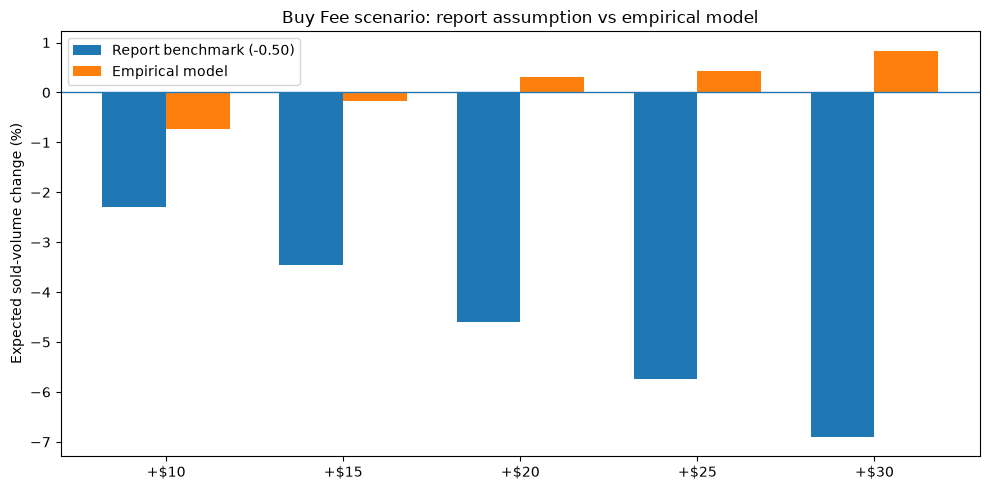

In [19]:
if len(portfolio_summary):
    x=np.arange(len(portfolio_summary))
    width=0.36
    fig,ax=plt.subplots(figsize=(10,5))
    ax.bar(x-width/2,portfolio_summary["Historical_Report_Volume_Change_Pct"]*100,width,label="Report benchmark (-0.50)")
    ax.bar(x+width/2,portfolio_summary["Model_Volume_Change_Pct"]*100,width,label="Empirical model")
    ax.set_xticks(x)
    ax.set_xticklabels([f"+${int(v)}" for v in portfolio_summary["Fee_Increase"]])
    ax.set_ylabel("Expected sold-volume change (%)")
    ax.set_title("Buy Fee scenario: report assumption vs empirical model")
    ax.axhline(0,linewidth=1)
    ax.legend()
    plt.tight_layout()
    plt.show()

## 17. Final decision table with evidence / reliability flags
A scenario is marked **HIGHER SUPPORT** when there are at least 30 historical events within ±$2.50 of that increase. This is an evidence-coverage flag, not a guarantee of forecast accuracy.

In [20]:
final_decision = portfolio_summary.merge(support_df,left_on="Fee_Increase",right_on="Scenario_Increase",how="left") if len(portfolio_summary) else pd.DataFrame()
if len(final_decision):
    final_decision["Historical_Support"] = np.where(final_decision["Historical_Events_Within_±2.5"]>=30,"HIGHER SUPPORT","LIMITED SUPPORT")
    final_decision=final_decision.drop(columns=["Scenario_Increase"])
    display(final_decision)

,Fee_Increase,Historical_Report_Volume_Change_Pct,Model_Volume_Change_Pct,Model_Conversion_Change_PP,Model_RPU_Change_Pct,Model_Revenue_Change_Pct,Baseline_Weekly_Sold,Predicted_Weekly_Sold,Baseline_Weekly_Revenue,Predicted_Weekly_Revenue,Historical_Events_Within_±2.5,Historical_Support
0,10,-0.022985,-0.007309,-1.784212,0.365123,0.112292,3131.25,3108.363619,1.103906e+06,1.165136e+06,330,HIGHER SUPPORT
1,15,-0.034478,-0.001811,-1.758370,0.393253,0.131410,3131.25,3125.578986,1.103906e+06,1.180862e+06,166,HIGHER SUPPORT
2,20,-0.045970,0.003122,-1.673912,0.390742,0.137858,3131.25,3141.024856,1.103906e+06,1.190474e+06,273,HIGHER SUPPORT
3,25,-0.057463,0.004373,-1.610686,0.397632,0.145061,3131.25,3144.942986,1.103906e+06,1.196126e+06,95,HIGHER SUPPORT
4,30,-0.068955,0.008373,-1.545362,0.407437,0.158561,3131.25,3157.468240,1.103906e+06,1.209159e+06,209,HIGHER SUPPORT


## 18. Export all review files
These outputs let Pricing / Analytics inspect every major step rather than relying only on a final prediction.

In [21]:
exports={
    "01_fee_change_event_audit.csv":events_all,
    "02_clean_fee_change_events.csv":events,
    "03_weekly_model_panel.csv":panel,
    "04_event_study.csv":event_df,
    "05_model_ready_events.csv":model_df_increase,
    "06_model_metrics.csv":metrics_df,
    "07_model_readiness.csv":readiness_df,
    "08_scenario_historical_support.csv":support_df,
    "09_scenario_detail.csv":scenario_detail,
    "10_portfolio_scenario_summary.csv":portfolio_summary,
    "11_final_decision_table.csv":final_decision,
    "12_report_elasticity_benchmark.csv":benchmark_summary,
}
for name,df in exports.items():
    if isinstance(df,pd.DataFrame):
        df.to_csv(OUTPUT_DIR/name,index=False)
print("Exported outputs to:",OUTPUT_DIR.resolve())

Exported outputs to: C:\Users\ViditSheth\OneDrive - America's Auto Auction\Finance - Documents\FP&A\Data Analytics\Development\Vidit_Sanbox\Buy Fee Model Phase 2\Rough Area\Volume Attirtion\buy_fee_model_outputs_v4


# How to interpret the final results

## 1. Validate the event count first
The model-ready event count should be materially lower than the VIN count. A single operational fee change may create several segment-level observations because different lanes and price tiers are distinct response units.

## 2. Do not judge model quality from training speed
The expensive work is reducing millions of VIN rows into clean weekly/event observations. Fitting Ridge and Random Forest on thousands or tens of thousands of event rows can legitimately take seconds.

## 3. Corporate-use standard
Treat the model as decision-support only when:
- the event definition audit is clean;
- chronological holdout R² is positive and reasonably stable;
- MAE beats the naive median benchmark;
- direction accuracy is meaningfully above 50%;
- the $10–$30 scenarios have adequate historical support;
- results are stable across 4/8/12-week windows and major locations/tiers.

## 4. Existing report validation
The existing report assumes roughly **-0.50 volume elasticity**. This notebook shows both that assumption and the empirically estimated response. A meaningful difference is evidence that the static report assumption should be recalibrated.

## 5. Business decision
The most useful scenario is not automatically the one with the largest RPU increase. Pricing should examine the joint impact on:
- sold-volume attrition;
- conversion;
- RPU;
- total Buy Fee revenue;
- historical support / uncertainty.

The final decision table provides those measures side-by-side for **+$10, +$15, +$20, +$25, and +$30**.